# Copy-paste conditions: donors, acceptors and the split

This notebook recomputes everything with the same code and settings as the Aqua `prepare`
job, then shows it. A check cell confirms it matches the job's real output.

**The rules**

| | Rule |
|---|---|
| **Frames used** | 1000–2461 (1,462 frames: 1,206 with fish, 256 empty background) |
| **Split** | 30-frame blocks (about 1 min each) assigned whole to train / val / test, split seed 2 |
| **Donor buffer** | any block within 15 frames (about 30 s) of a donor frame is forced into **train**, so no val/test frame is near a donor |
| **Donors** (fish that get cut out) | only the ones you approved in review, plus the Forcepsfish you annotated outside the frame range (163–166, 939–941). A donor must be in a **train** frame or outside 1000–2461 entirely |
| **Acceptors** (frames a fish is pasted into) | any **train** frame in an **allowed camera view** (not the pole / open-water view), whatever species it contains |
| **Never touched** | val and test frames: no pasting into them, no donors from them |
| **Each paste** | random rotation within ±20°, horizontal flip 50% of the time, no vertical flip, no resizing, never overlapping a real fish's box; edge-only Poisson blend |
| **How many** | 150 synthetic images per species, one pasted fish each, donors reused evenly |

To see the finished pasted images at full size, use `copy_paste_preview.ipynb`.

In [1]:
import csv
import json
import random
import sys
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from IPython.display import Markdown, display


def _find_package_dir() -> Path:
    candidates = []
    nb_file = globals().get("__vsc_ipynb_file__")
    if nb_file:
        candidates.append(Path(nb_file).resolve().parent)
    cwd = Path.cwd()
    candidates += [cwd, cwd / "copy_paste_experiment"]
    p = cwd
    for _ in range(4):
        p = p.parent
        candidates += [p, p / "copy_paste_experiment"]
    candidates.append(Path.home() / "Desktop" / "EGH490-2_scripts" / "copy_paste_experiment")
    needed = ["prepare_experiment.py", "labels_export/data.yaml", "experiment_donors.csv",
              "approved_acceptor_frames.csv"]
    for c in candidates:
        if all((c / f).exists() for f in needed) and (c.parent / "full_dataset").is_dir():
            return c.resolve()
    raise FileNotFoundError("Couldn't find the unzipped copy_paste_experiment folder (with labels_export/ "
                            "inside and full_dataset/ next to it). Checked:\n  " + "\n  ".join(map(str, candidates)))


PKG = _find_package_dir()
IMAGES_DIR = PKG.parent / "full_dataset"
if str(PKG) not in sys.path:
    sys.path.insert(0, str(PKG))
sys.modules.pop("prepare_experiment", None)
import prepare_experiment as pe

# exactly the settings the Aqua job uses (its defaults)
_argv, sys.argv = sys.argv, ["prepare_experiment.py", "--images-dir", str(IMAGES_DIR)]
args = pe.parse_args()
sys.argv = _argv
print(f"experiment folder: {PKG}")

experiment folder: ../copy_paste_experiment


## Recompute the plan

These are the same steps `prepare_experiment.py` runs before it writes anything: read the
labels, match your donors to their polygons, split the frames, and work out which donors and
acceptor frames are allowed.

In [2]:
W, H = 1280, 720
names = pe.read_names(args.names_yaml)
name_to_id = {v: k for k, v in names.items()}
focus = [s.strip() for s in args.species.split(",")]
focus_ids = [name_to_id[s] for s in focus]
labels = pe.read_export_labels(args.labels_dir)
frames = list(range(args.min_frame, args.max_frame + 1))
frame_classes = {f: [c for c, _ in labels.get(f, [])] for f in frames}

donors = []
for r in csv.DictReader(open(args.donors_csv)):
    if r["species"] not in focus:
        continue
    cid, fr = name_to_id[r["species"]], int(r["frame"])
    box = tuple(float(r[k]) for k in ("bbox_x", "bbox_y", "bbox_w", "bbox_h"))
    cands = [(pe.iou(box, pe.poly_bbox_px(poly, W, H)), poly) for c, poly in labels.get(fr, []) if c == cid]
    best = max(cands, key=lambda t: t[0]) if cands else (0.0, None)
    if best[0] >= 0.8:
        donors.append({"species": r["species"], "frame": fr, "poly": best[1], "source": r["source"],
                       "review_index": r["review_gallery_index"], "iou": best[0]})

donor_frames_in_range = sorted({d["frame"] for d in donors if args.min_frame <= d["frame"] <= args.max_frame})
split, block_of, protected = pe.make_split(frames, frame_classes, focus_ids, donor_frames_in_range, args)
acceptor_view = {int(r["frame"]): r["allowed_as_acceptor"] == "1" for r in csv.DictReader(open(args.acceptor_csv))}
acceptors = [f for f in frames if split[f] == "train" and acceptor_view.get(f, False)]

# Your acceptor review: one frame per minute, kept (1) or dropped (0). Used only to label WHY a
# frame is excluded: inside a run of dropped minutes = pole / open-water view; between a kept and a
# dropped minute = the camera was turning, excluded to be safe.
REVIEW = [(1016, 0), (1054, 0), (1075, 0), (1105, 0), (1140, 1), (1159, 1), (1243, 1), (1264, 1), (1285, 1),
          (1315, 1), (1349, 1), (1380, 1), (1404, 0), (1457, 0), (1464, 0), (1495, 0), (1528, 0), (1555, 0),
          (1587, 0), (1615, 1), (1645, 1), (1674, 1), (1705, 1), (1735, 1), (1764, 1), (1795, 0), (1824, 0),
          (1855, 0), (1884, 0), (1915, 1), (1945, 1), (1974, 1), (2002, 0), (2036, 1), (2062, 1), (2091, 1),
          (2118, 1), (2158, 1), (2182, 1), (2215, 0), (2245, 0), (2274, 0), (2303, 0), (2333, 0), (2365, 0),
          (2395, 1), (2420, 1), (2454, 1), (2485, 1), (2515, 1), (2545, 1), (2575, 1), (2605, 0), (2635, 0),
          (2665, 0), (2695, 0), (2725, 1), (2755, 1), (2785, 1), (2815, 1), (2816, 1)]


def view_reason(f):
    if acceptor_view.get(f, False):
        return "allowed"
    for a, k in REVIEW:
        if a == f:
            return "pole" if not k else "allowed"
    if f < REVIEW[0][0]:
        return "pole"
    for (a, ka), (b, kb) in zip(REVIEW, REVIEW[1:]):
        if a < f < b:
            return "pole" if (ka == 0 and kb == 0) else "turning"
    return "pole"


reason = {f: view_reason(f) for f in frames}
usable = [d for d in donors if not (args.min_frame <= d["frame"] <= args.max_frame) or split[d["frame"]] == "train"]
print(f"{len(donors)} donors matched, {len(usable)} usable · {len(acceptors)} acceptor frames")

36 donors matched, 36 usable · 539 acceptor frames


## Check: does this match what the Aqua job produces?

`copy_paste_preview.ipynb` ran the real `prepare_experiment.py` and saved its split and summary
in `preview_data/`. If that folder exists, this cell compares against it.

In [3]:
prev = PKG / "preview_data"
if (prev / "split.csv").exists():
    real_split = {int(r["frame"]): r["split"] for r in csv.DictReader(open(prev / "split.csv"))}
    summ = json.loads((prev / "prepare_summary.json").read_text())
    same_split = real_split == split
    same_donors = all(summ["focus"][s]["donors_usable"] == sum(d["species"] == s for d in usable) for s in focus)
    print(f"split identical to the real job's: {same_split}")
    print(f"usable donor counts identical:     {same_donors}")
    if not (same_split and same_donors):
        print("MISMATCH -- tell Claude before trusting this notebook")
else:
    print("preview_data/ not found -- run copy_paste_preview.ipynb first if you want this check")

split identical to the real job's: True
usable donor counts identical:     True


## Counts

In [4]:
n_split = Counter(split.values())
rows = ["| | Train | Val | Test |", "|---|---|---|---|",
        f"| Frames | {n_split['train']} | {n_split['val']} | {n_split['test']} |"]
for s, cid in zip(focus, focus_ids):
    c = Counter(split[f] for f in frames for x in frame_classes[f] if x == cid)
    rows.append(f"| {s} instances | {c['train']} | {c['val']} | {c['test']} |")
display(Markdown("**Split**\n\n" + "\n".join(rows)))

rows = ["| Species | Approved in review | Added (outside 1000–2461) | Usable donors | Acceptor frames | Synthetic images |",
        "|---|---|---|---|---|---|"]
for s in focus:
    ds = [d for d in usable if d["species"] == s]
    rows.append(f"| {s} | {sum(d['source'] == 'approved_in_review' for d in ds)} | "
                f"{sum(d['source'] != 'approved_in_review' for d in ds)} | {len(ds)} | {len(acceptors)} | "
                f"{args.synth_per_species} |")
n_pole = sum(1 for f in frames if split[f] == "train" and reason[f] == "pole")
n_turn = sum(1 for f in frames if split[f] == "train" and reason[f] == "turning")
display(Markdown("**Donors and acceptors**\n\n" + "\n".join(rows) +
                 f"\n\nOf the {n_split['train']} train frames, **{len(acceptors)}** can take a paste. "
                 f"**{n_pole}** are the pole / open-water view, and **{n_turn}** fall in a minute where the camera was "
                 f"turning, so they're excluded to be safe. The same {len(acceptors)} acceptor frames serve both species."))

**Split**

| | Train | Val | Test |
|---|---|---|---|
| Frames | 982 | 240 | 240 |
| Forcepsfish instances | 56 | 16 | 21 |
| Moorish Idol instances | 85 | 29 | 29 |

**Donors and acceptors**

| Species | Approved in review | Added (outside 1000–2461) | Usable donors | Acceptor frames | Synthetic images |
|---|---|---|---|---|---|
| Forcepsfish | 13 | 10 | 23 | 539 | 150 |
| Moorish Idol | 13 | 0 | 13 | 539 | 150 |

Of the 982 train frames, **539** can take a paste. **260** are the pole / open-water view, and **183** fall in a minute where the camera was turning, so they're excluded to be safe. The same 539 acceptor frames serve both species.

## Timeline: where everything sits in the footage

Frame numbers run left to right (about 30 frames = 1 minute).

- **Split:** which side each block went to.
- **Camera view:** dark = the pole / open-water view; mid-grey = a minute where the camera was turning (also excluded, to be safe).
- **Can take a paste:** the acceptor frames, meaning train AND an allowed view.
- **Donor frames:** the source of each donor fish, with its 15-frame buffer shaded grey. Every shaded area is train.

The Forcepsfish donors from frames 163–166 and 939–941 sit outside this range, so they aren't on the chart.

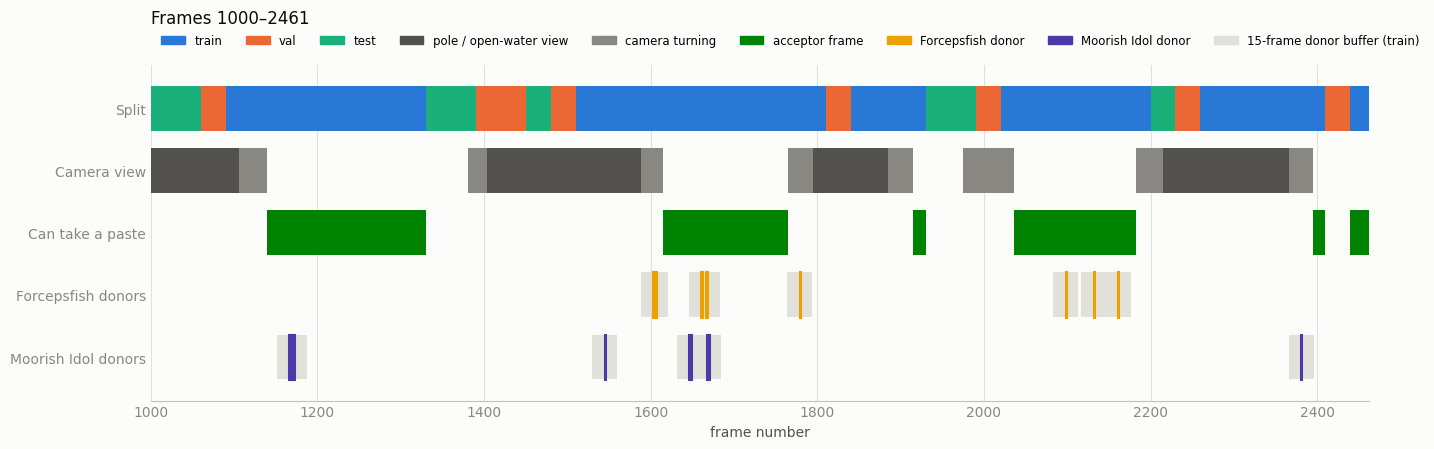

In [5]:
SPLIT_C = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
SP_C = {"Forcepsfish": "#eda100", "Moorish Idol": "#4a3aa7"}
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"

fig, ax = plt.subplots(figsize=(15, 4.6), facecolor=SURF)
ax.set_facecolor(SURF)
lanes = {"Split": 4, "Camera view": 3, "Can take a paste": 2, "Forcepsfish donors": 1, "Moorish Idol donors": 0}


def runs(pred):
    out, start = [], None
    for f in frames + [None]:
        ok = f is not None and pred(f)
        if ok and start is None:
            start = f
        if not ok and start is not None:
            out.append((start, f if f is not None else frames[-1] + 1))
            start = None
    return out


for sp_name, col in SPLIT_C.items():
    for a, b in runs(lambda f, s=sp_name: split[f] == s):
        ax.add_patch(plt.Rectangle((a, lanes["Split"] - 0.36), b - a, 0.72, color=col, lw=0))
for why, col in (("pole", INK2), ("turning", MUTED)):
    for a, b in runs(lambda f, w=why: reason[f] == w):
        ax.add_patch(plt.Rectangle((a, lanes["Camera view"] - 0.36), b - a, 0.72, color=col, lw=0))
for a, b in runs(lambda f: f in set(acceptors)):
    ax.add_patch(plt.Rectangle((a, lanes["Can take a paste"] - 0.36), b - a, 0.72, color="#008300", lw=0))
for s in focus:
    lane = lanes[f"{s} donors"]
    for f in sorted({d["frame"] for d in usable if d["species"] == s and args.min_frame <= d["frame"] <= args.max_frame}):
        ax.add_patch(plt.Rectangle((f - args.guard_frames, lane - 0.36), 2 * args.guard_frames, 0.72,
                                   color=GRID, lw=0, zorder=1))
        ax.plot([f, f], [lane - 0.36, lane + 0.36], color=SP_C[s], lw=2.2, zorder=3)

ax.set_xlim(args.min_frame, args.max_frame + 1)
ax.set_ylim(-0.7, 4.7)
ax.set_yticks(list(lanes.values()))
ax.set_yticklabels(list(lanes.keys()), color=INK2)
ax.set_xlabel("frame number", color=INK2)
ax.xaxis.grid(True, color=GRID, lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(colors=MUTED, length=0)
handles = [Patch(color=SPLIT_C["train"], label="train"), Patch(color=SPLIT_C["val"], label="val"),
           Patch(color=SPLIT_C["test"], label="test"),
           Patch(color=INK2, label="pole / open-water view"), Patch(color=MUTED, label="camera turning"),
           Patch(color="#008300", label="acceptor frame"),
           Patch(color=SP_C["Forcepsfish"], label="Forcepsfish donor"),
           Patch(color=SP_C["Moorish Idol"], label="Moorish Idol donor"),
           Patch(color=GRID, label="15-frame donor buffer (train)")]
ax.legend(handles=handles, ncol=9, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.02), fontsize=8.5)
ax.set_title(f"Frames {args.min_frame}–{args.max_frame}", loc="left", color=INK, pad=30, fontsize=12)
plt.tight_layout()
plt.show()

## Donors: every fish that can be cut out

The outline is the polygon used as the mask. Each tile shows the frame, where the donor came
from (your review gallery number, or "added" for the out-of-range Forcepsfish you annotated),
and its size in pixels.

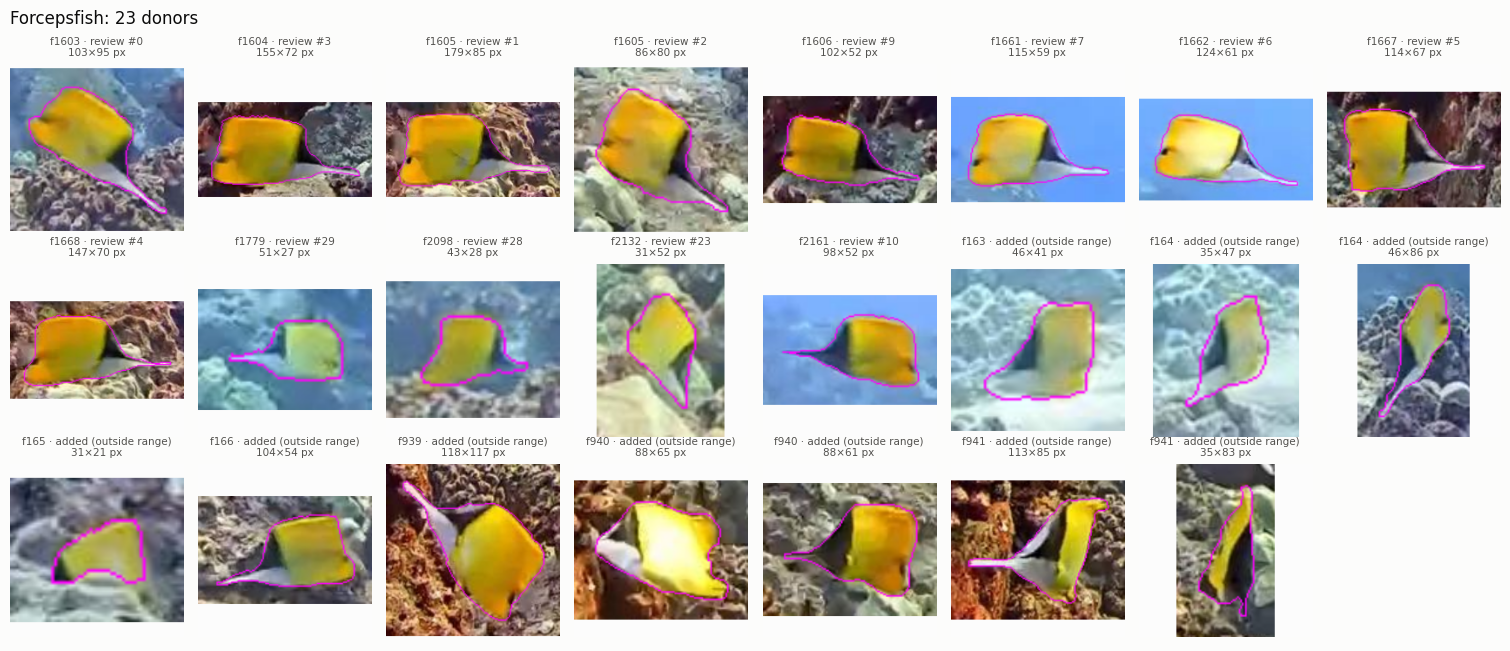

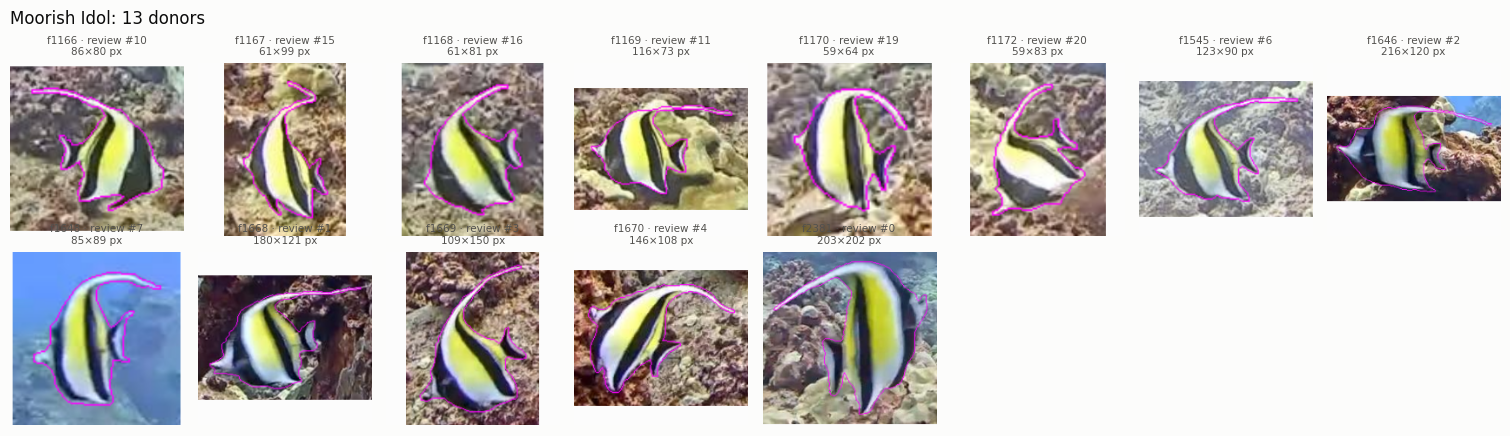

In [6]:
def rgb(f):
    return cv2.cvtColor(cv2.imread(str(IMAGES_DIR / f"frame_{f}.jpg")), cv2.COLOR_BGR2RGB)


def donor_tile(d, size=200, pad=14):
    img = rgb(d["frame"])
    pts = np.round(d["poly"] * [W, H]).astype(np.int32)
    x0, y0 = pts.min(0)
    x1, y1 = pts.max(0)
    cv2.polylines(img, [pts], True, (255, 0, 255), 1)
    crop = img[max(0, y0 - pad):min(H, y1 + pad), max(0, x0 - pad):min(W, x1 + pad)]
    s = size / max(crop.shape[:2])
    crop = cv2.resize(crop, (max(1, int(crop.shape[1] * s)), max(1, int(crop.shape[0] * s))))
    tile = np.full((size, size, 3), 252, np.uint8)
    oy, ox = (size - crop.shape[0]) // 2, (size - crop.shape[1]) // 2
    tile[oy:oy + crop.shape[0], ox:ox + crop.shape[1]] = crop
    return tile, (x1 - x0, y1 - y0)


for s in focus:
    ds = sorted([d for d in usable if d["species"] == s], key=lambda d: (d["source"] != "approved_in_review", d["frame"]))
    cols = 8
    rows_n = -(-len(ds) // cols)
    fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 1.9, rows_n * 2.2), facecolor=SURF)
    for ax_, d in zip(axes.ravel(), ds):
        tile, (w, h) = donor_tile(d)
        ax_.imshow(tile)
        where = f"review #{d['review_index']}" if d["source"] == "approved_in_review" else "added (outside range)"
        ax_.set_title(f"f{d['frame']} · {where}\n{w}×{h} px", fontsize=7.5, color=INK2)
    for ax_ in axes.ravel():
        ax_.axis("off")
    fig.suptitle(f"{s}: {len(ds)} donors", x=0.01, ha="left", fontsize=12, color=INK)
    plt.tight_layout()
    plt.show()

## Acceptors: frames a fish can be pasted into

A random sample of the acceptor frames, each labelled with what's already in it. Any species,
or none, is fine.

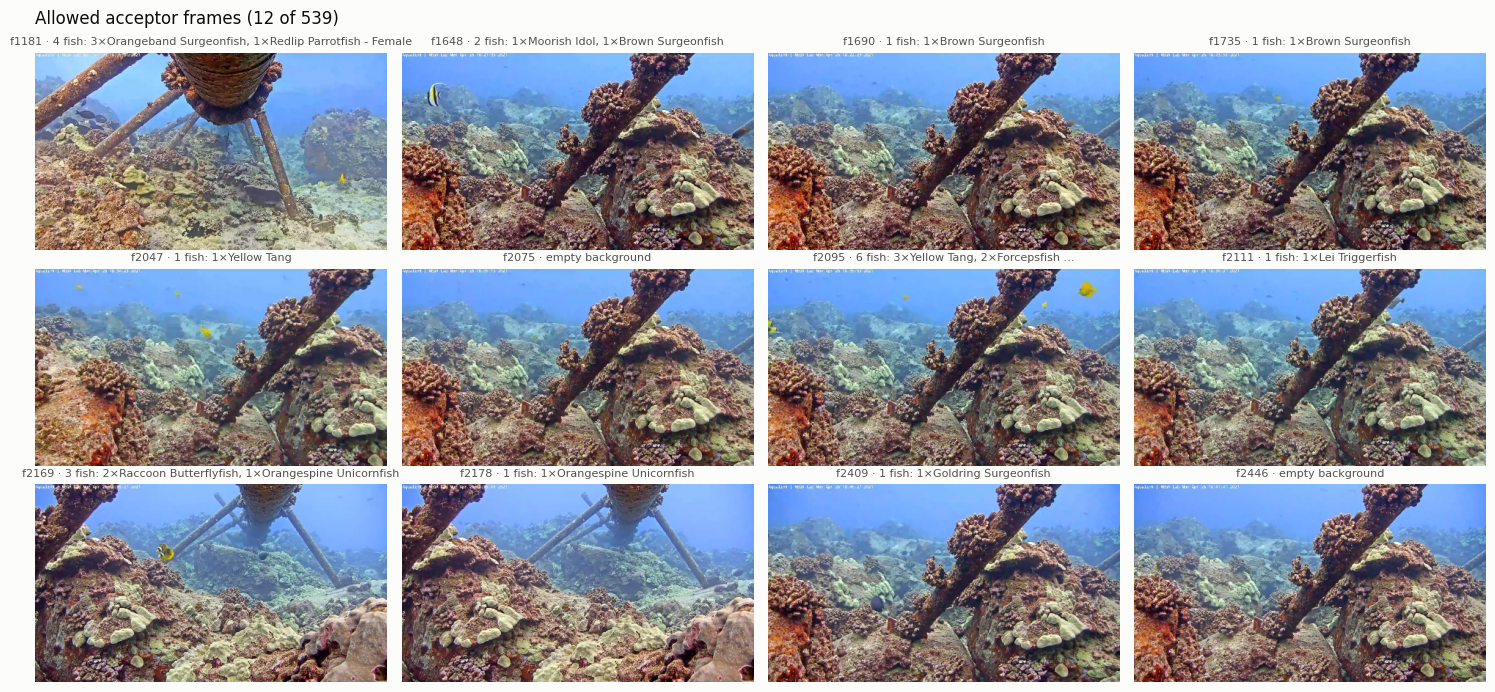

In [7]:
rng = random.Random(0)


def frame_grid(frame_list, captions, title, cols=4):
    rows_n = -(-len(frame_list) // cols)
    fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 3.7, rows_n * 2.35), facecolor=SURF)
    for ax_, f, cap in zip(np.ravel(axes), frame_list, captions):
        ax_.imshow(cv2.resize(rgb(f), (480, 270)))
        ax_.set_title(cap, fontsize=8, color=INK2)
    for ax_ in np.ravel(axes):
        ax_.axis("off")
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, color=INK)
    plt.tight_layout()
    plt.show()


def contents(f):
    c = Counter(names[x] for x in frame_classes[f])
    if not c:
        return "empty background"
    top = ", ".join(f"{n}×{k}" for k, n in c.most_common(2))
    return f"{sum(c.values())} fish: {top}" + (" …" if len(c) > 2 else "")


sample = sorted(rng.sample(acceptors, 12))
frame_grid(sample, [f"f{f} · {contents(f)}" for f in sample], f"Allowed acceptor frames (12 of {len(acceptors)})")

## Frames that can NOT take a paste, and why

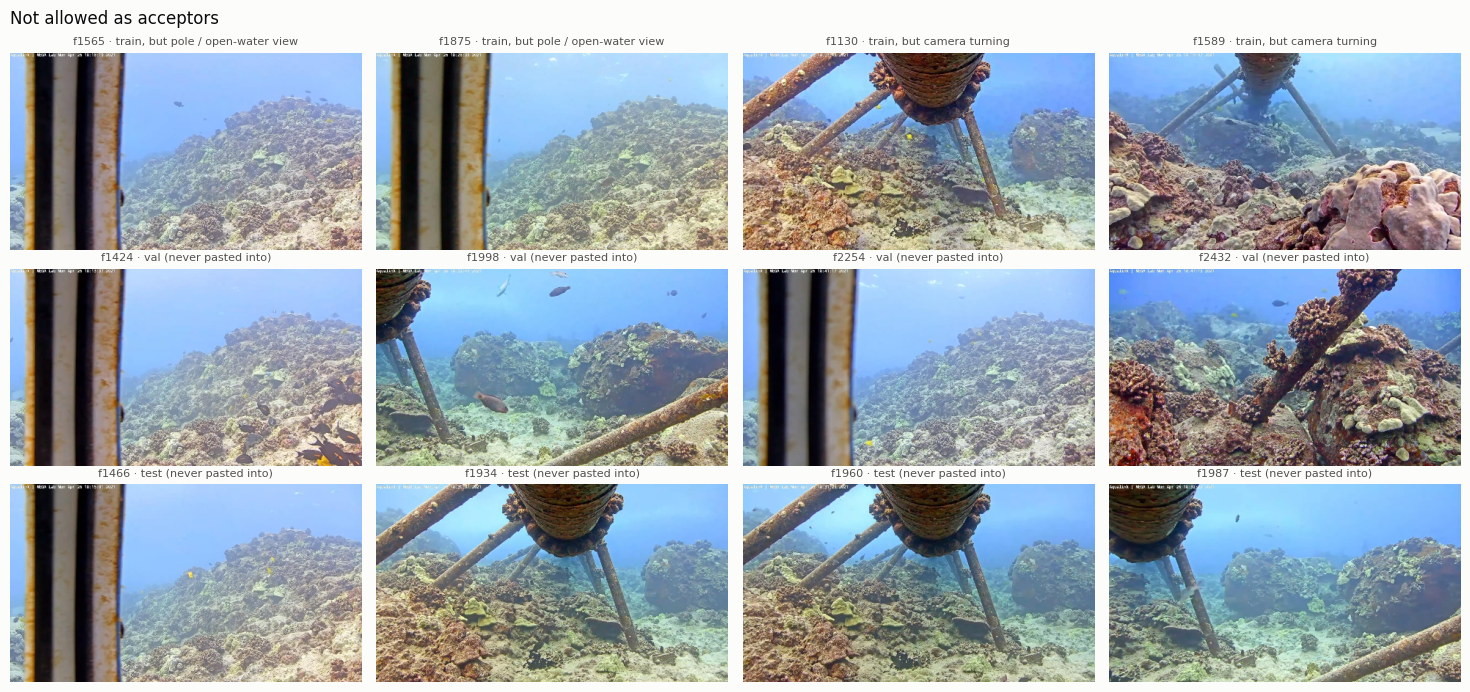

In [8]:
pole = sorted(rng.sample([f for f in frames if split[f] == "train" and reason[f] == "pole"], 2))
turn = sorted(rng.sample([f for f in frames if split[f] == "train" and reason[f] == "turning"], 2))
val_f = sorted(rng.sample([f for f in frames if split[f] == "val"], 4))
test_f = sorted(rng.sample([f for f in frames if split[f] == "test"], 4))
frame_grid(pole + turn + val_f + test_f,
           [f"f{f} · train, but pole / open-water view" for f in pole]
           + [f"f{f} · train, but camera turning" for f in turn]
           + [f"f{f} · val (never pasted into)" for f in val_f]
           + [f"f{f} · test (never pasted into)" for f in test_f],
           "Not allowed as acceptors")